In [2]:
import numpy as np
import pandas as pd
from datetime import datetime
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from xgboost import XGBRegressor
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import ConvLSTM2D, Dense, Flatten, Dropout
from tensorflow.keras.optimizers import Adam

In [ ]:
df = pd.read_csv(r"C:\Users\ASUS\Downloads\nifty50latest_stock.csv")
# Remove 2nd and 3rd rows (Python uses zero-based indexing)
df = df.drop([1, 2]).reset_index(drop=True)

# Optional: verify
print(df.head(5))


        Price        Close         High          Low         Open  Volume
0      Ticker        ^NSEI        ^NSEI        ^NSEI        ^NSEI   ^NSEI
1  05-01-2015  8378.400391  8445.599609  8363.900391  8407.950195  118200
2  06-01-2015  8127.350098  8327.849609  8111.350098  8325.299805  172800
3  07-01-2015  8102.100098  8151.200195  8065.450195  8118.649902  164100
4  08-01-2015  8234.599609       8243.5  8167.299805  8191.399902  143800


In [4]:
# Assuming your DataFrame is named df
df = df.drop(index=0).reset_index(drop=True)

# Optional: confirm it worked
print(df.head())


        Price        Close         High          Low         Open  Volume
0  05-01-2015  8378.400391  8445.599609  8363.900391  8407.950195  118200
1  06-01-2015  8127.350098  8327.849609  8111.350098  8325.299805  172800
2  07-01-2015  8102.100098  8151.200195  8065.450195  8118.649902  164100
3  08-01-2015  8234.599609       8243.5  8167.299805  8191.399902  143800
4  09-01-2015       8284.5  8303.299805  8190.799805  8285.450195  148000


In [5]:
df.columns = ['Date', 'Open', 'High', 'Low', 'Close', 'Volume']  # rename manually

In [6]:
for col in df.columns:
    if col != 'Date':
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Optional: fill missing values created by coercion
df = df.fillna(method='ffill').fillna(method='bfill')

# Confirm that everything is now numeric
print(df.dtypes)

Date       object
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object


C:\Users\ASUS\AppData\Local\Temp\ipykernel_75564\1277827392.py:6: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='ffill').fillna(method='bfill')


In [7]:
df['Date'] = pd.to_datetime(df['Date'], format='%d-%m-%Y')
df = df.sort_values('Date').reset_index(drop=True)

# Create lag features
for lag in range(1, 6):
    df[f'Open_lag_{lag}'] = df['Open'].shift(lag)
    df[f'Close_lag_{lag}'] = df['Close'].shift(lag)
    df[f'High_lag_{lag}'] = df['High'].shift(lag)
    df[f'Low_lag_{lag}'] = df['Low'].shift(lag)

# Rolling mean and std
df['MA_5'] = df['Close'].rolling(window=5).mean()
df['STD_5'] = df['Close'].rolling(window=5).std()

# Date-time features
df['DayOfWeek'] = df['Date'].dt.dayofweek
df['Month'] = df['Date'].dt.month

# Drop NaN
df = df.dropna().reset_index(drop=True)

# ------------------------------------------------------------
# STEP 2: DEFINE FEATURES & TARGETS
# ------------------------------------------------------------
features = [col for col in df.columns if col not in ['Date', 'High', 'Low']]
X = df[features]
y_high = df['High']
y_low = df['Low']

# Train-Test Split (no shuffle, to preserve time order)
split_ratio = 0.9
split_idx = int(len(df) * split_ratio)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_high_train, y_high_test = y_high.iloc[:split_idx], y_high.iloc[split_idx:]
y_low_train, y_low_test = y_low.iloc[:split_idx], y_low.iloc[split_idx:]

# Scale
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ------------------------------------------------------------
# STEP 3: XGBOOST MODELS (TABULAR)
# ------------------------------------------------------------
xgb_high = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6)
xgb_low = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6)

xgb_high.fit(X_train_scaled, y_high_train)
xgb_low.fit(X_train_scaled, y_low_train)

pred_high_xgb = xgb_high.predict(X_test_scaled)
pred_low_xgb = xgb_low.predict(X_test_scaled)

# ------------------------------------------------------------
# STEP 4: ConvLSTM MODEL (SEQUENTIAL)
# ------------------------------------------------------------
def create_sequences(X, y_high, y_low, seq_len=5):
    X_seq, yh_seq, yl_seq = [], [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        yh_seq.append(y_high[i])
        yl_seq.append(y_low[i])
    return np.array(X_seq), np.array(yh_seq), np.array(yl_seq)

seq_len = 5
X_scaled_full = scaler.fit_transform(X)
X_seq, y_high_seq, y_low_seq = create_sequences(X_scaled_full, y_high.values, y_low.values, seq_len)

split_idx_seq = int(len(X_seq) * split_ratio)
X_train_seq, X_test_seq = X_seq[:split_idx_seq], X_seq[split_idx_seq:]
y_high_train_seq, y_high_test_seq = y_high_seq[:split_idx_seq], y_high_seq[split_idx_seq:]
y_low_train_seq, y_low_test_seq = y_low_seq[:split_idx_seq], y_low_seq[split_idx_seq:]

# Reshape for ConvLSTM: [samples, timesteps, rows, cols, features]
X_train_seq = X_train_seq.reshape((X_train_seq.shape[0], seq_len, 1, 1, X_train_seq.shape[2]))
X_test_seq = X_test_seq.reshape((X_test_seq.shape[0], seq_len, 1, 1, X_test_seq.shape[2]))

model = Sequential([
    ConvLSTM2D(32, (1,1), activation='relu', input_shape=(seq_len, 1, 1, X_train_seq.shape[-1]), return_sequences=True),
    Dropout(0.2),
    ConvLSTM2D(16, (1,1), activation='relu'),
    Flatten(),
    Dense(64, activation='relu'),
    Dense(2)
])
model.compile(optimizer=Adam(0.001), loss='mse')

y_train_seq_combined = np.column_stack((y_high_train_seq, y_low_train_seq))
y_test_seq_combined = np.column_stack((y_high_test_seq, y_low_test_seq))

history = model.fit(
    X_train_seq, y_train_seq_combined,
    epochs=25, batch_size=16, validation_data=(X_test_seq, y_test_seq_combined),
    verbose=1
)

pred_seq = model.predict(X_test_seq)
pred_high_conv, pred_low_conv = pred_seq[:,0], pred_seq[:,1]

# ------------------------------------------------------------
# STEP 5: ENSEMBLE (WEIGHTED AVERAGE)
# ------------------------------------------------------------
# Align sequence-based test predictions with tabular test indices
min_len = min(len(pred_high_conv), len(pred_high_xgb))
pred_high_ensemble = 0.6 * pred_high_conv[-min_len:] + 0.4 * pred_high_xgb[-min_len:]
pred_low_ensemble  = 0.6 * pred_low_conv[-min_len:]  + 0.4 * pred_low_xgb[-min_len:]

y_high_true = y_high_test.values[-min_len:]
y_low_true = y_low_test.values[-min_len:]

# ------------------------------------------------------------
# STEP 6: METRICS
# ------------------------------------------------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

m_high = metrics(y_high_true, pred_high_ensemble, "High (Ensemble)")
m_low = metrics(y_low_true, pred_low_ensemble, "Low (Ensemble)")

# ------------------------------------------------------------
# STEP 7: VISUAL COMPARISONS
# ------------------------------------------------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High", color='blue')
plt.plot(pred_high_ensemble, label="Predicted High (Ensemble)", color='orange', linestyle='--')
plt.title("NIFTY 50: Actual vs Predicted High")
plt.legend()
plt.grid(True)
plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true, label="Actual Low", color='green')
plt.plot(pred_low_ensemble, label="Predicted Low (Ensemble)", color='red', linestyle='--')
plt.title("NIFTY 50: Actual vs Predicted Low")
plt.legend()
plt.grid(True)
plt.show()

# Optional: plot combined
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High", color='blue', alpha=0.6)
plt.plot(pred_high_ensemble, label="Pred High", color='orange', alpha=0.7)
plt.plot(y_low_true, label="Actual Low", color='green', alpha=0.6)
plt.plot(pred_low_ensemble, label="Pred Low", color='red', alpha=0.7)
plt.title("NIFTY 50: Actual vs Ensemble Prediction (High & Low)")
plt.legend()
plt.grid(True)
plt.show()

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/25


KeyboardInterrupt: 


📊 High (XGBoost) Metrics:
MAE  : 266.965
RMSE : 389.295
R²   : 0.812
MAPE : 1.07%

📊 Low (XGBoost) Metrics:
MAE  : 247.410
RMSE : 360.477
R²   : 0.846
MAPE : 1.00%


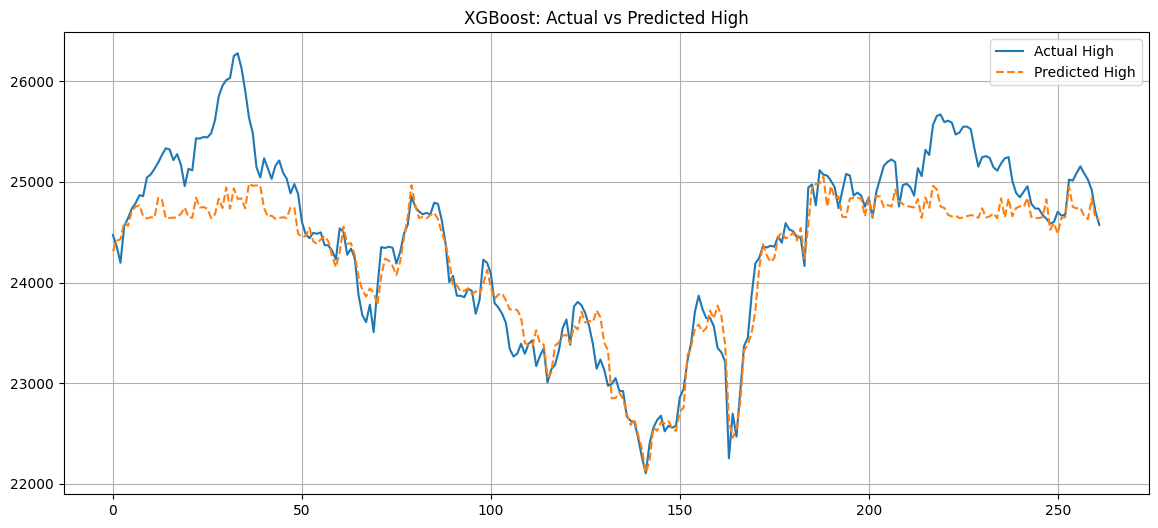

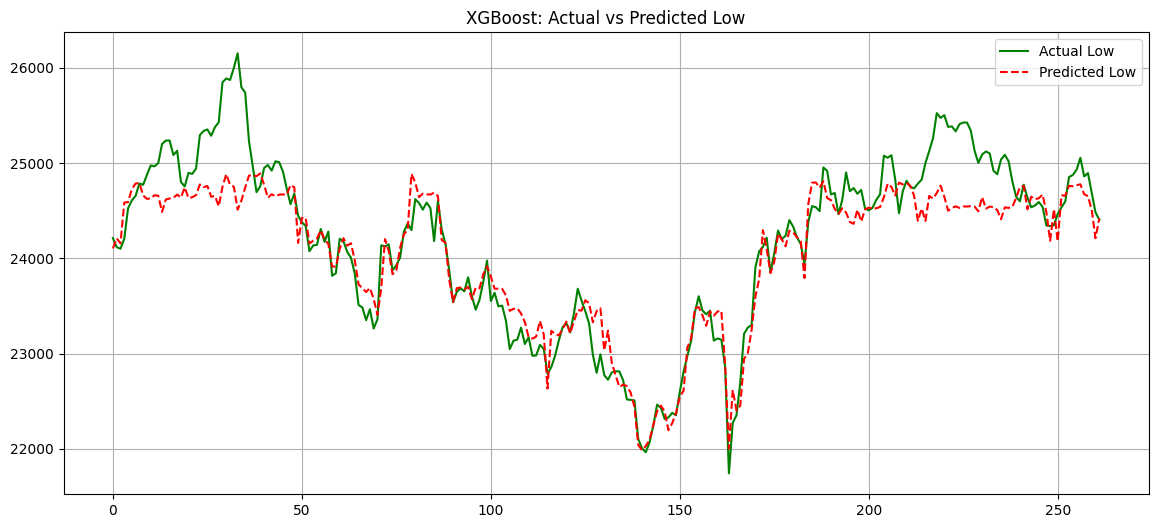

In [8]:
for lag in range(1,6):
    df[f'Open_lag_{lag}'] = df['Open'].shift(lag)
    df[f'Close_lag_{lag}'] = df['Close'].shift(lag)
    df[f'High_lag_{lag}'] = df['High'].shift(lag)
    df[f'Low_lag_{lag}'] = df['Low'].shift(lag)

# Drop NaNs
df = df.dropna().reset_index(drop=True)

# Features & target
features = [col for col in df.columns if col not in ['Date', 'High', 'Low']]
X = df[features]
y_high = df['High']
y_low = df['Low']

# Train-test split (no shuffle)
split_idx = int(len(df)*0.9)
X_train, X_test = X.iloc[:split_idx], X.iloc[split_idx:]
y_high_train, y_high_test = y_high.iloc[:split_idx], y_high.iloc[split_idx:]
y_low_train, y_low_test = y_low.iloc[:split_idx], y_low.iloc[split_idx:]

# Scaling
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ------------------ TRAIN XGBOOST ------------------
xgb_high = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6)
xgb_low = XGBRegressor(n_estimators=400, learning_rate=0.05, max_depth=6)

xgb_high.fit(X_train_scaled, y_high_train)
xgb_low.fit(X_train_scaled, y_low_train)

# Predict
pred_high = xgb_high.predict(X_test_scaled)
pred_low = xgb_low.predict(X_test_scaled)

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_test, pred_high, "High (XGBoost)")
metrics(y_low_test, pred_low, "Low (XGBoost)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_test.values, label="Actual High")
plt.plot(pred_high, label="Predicted High", linestyle='--')
plt.title("XGBoost: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_test.values, label="Actual Low", color='green')
plt.plot(pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("XGBoost: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()

In [9]:
from tensorflow.keras.layers import LSTM, Dense, Dropout

Epoch 1/25


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 2ms/step - loss: 0.1010 - val_loss: 0.0095
Epoch 2/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0209 - val_loss: 0.0041
Epoch 3/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0191 - val_loss: 0.0184
Epoch 4/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0174 - val_loss: 0.0154
Epoch 5/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0162 - val_loss: 0.0098
Epoch 6/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0151 - val_loss: 0.0031
Epoch 7/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0157 - val_loss: 0.0031
Epoch 8/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0153 - val_loss: 0.0092
Epoch 9/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0152 - val_loss: 0.0065
Epoch 10/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0156 - val_loss: 0.0023
Epoch 11/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0130 - val_loss: 0.0084
Epoch 12/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.

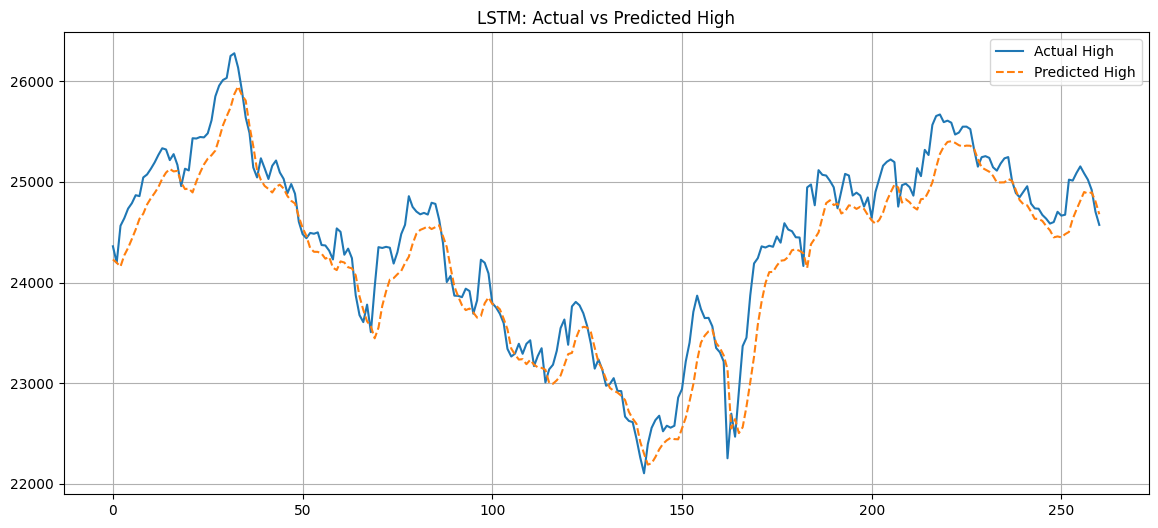

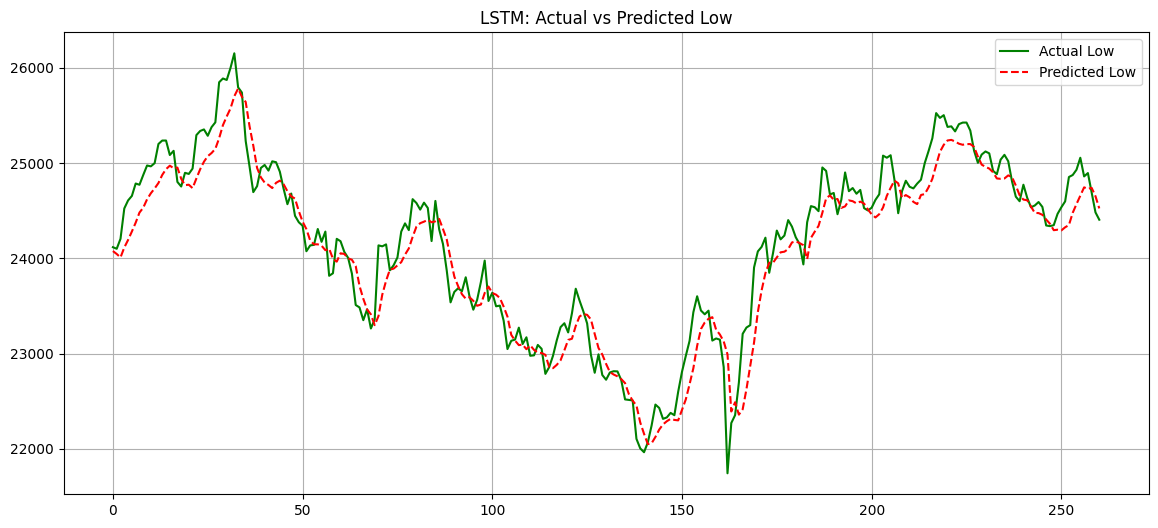

In [ ]:
features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y_high = df['High'].values
y_low = df['Low'].values

# Scaling
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(df[['High','Low']].values)

# ------------------ CREATE SEQUENCES ------------------
def create_seq(X, y, seq_len=5):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 5
X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# ------------------ LSTM MODEL ------------------
model = Sequential([
    LSTM(50, activation='relu', input_shape=(seq_len, X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(2)
])
model.compile(optimizer='adam', loss='mse')

# Train
history = model.fit(X_train, y_train, epochs=25, batch_size=16, validation_data=(X_test, y_test), verbose=1)

# Predict
pred = model.predict(X_test)
pred_inv = scaler_y.inverse_transform(pred)
y_test_inv = scaler_y.inverse_transform(y_test)

pred_high, pred_low = pred_inv[:,0], pred_inv[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, pred_high, "High (LSTM)")
metrics(y_low_true, pred_low, "Low (LSTM)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High")
plt.plot(pred_high, label="Predicted High", linestyle='--')
plt.title("LSTM: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true, label="Actual Low", color='green')
plt.plot(pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("LSTM: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()

In [19]:
from sklearn.preprocessing import MinMaxScaler

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 2s 4ms/step - loss: 0.2675 - val_loss: 0.0294
Epoch 2/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0191 - val_loss: 0.0049
Epoch 3/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0167 - val_loss: 0.0083
Epoch 4/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0172 - val_loss: 0.0137
Epoch 5/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0149 - val_loss: 0.0061
Epoch 6/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0145 - val_loss: 0.0143
Epoch 7/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0139 - val_loss: 0.0060
Epoch 8/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0127 - val_loss: 0.0180
Epoch 9/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0141 - val_loss: 0.0137
Epoch 10/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0134 - val_loss: 0.0121
Epoch 11/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0134 - val_loss: 0.0057
Epoch 12/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step

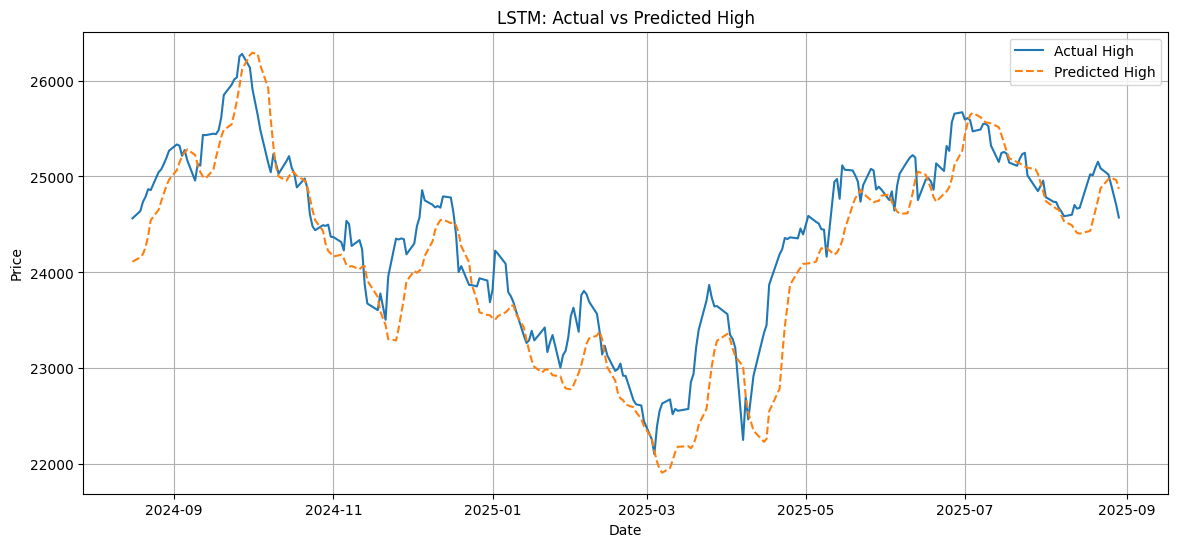

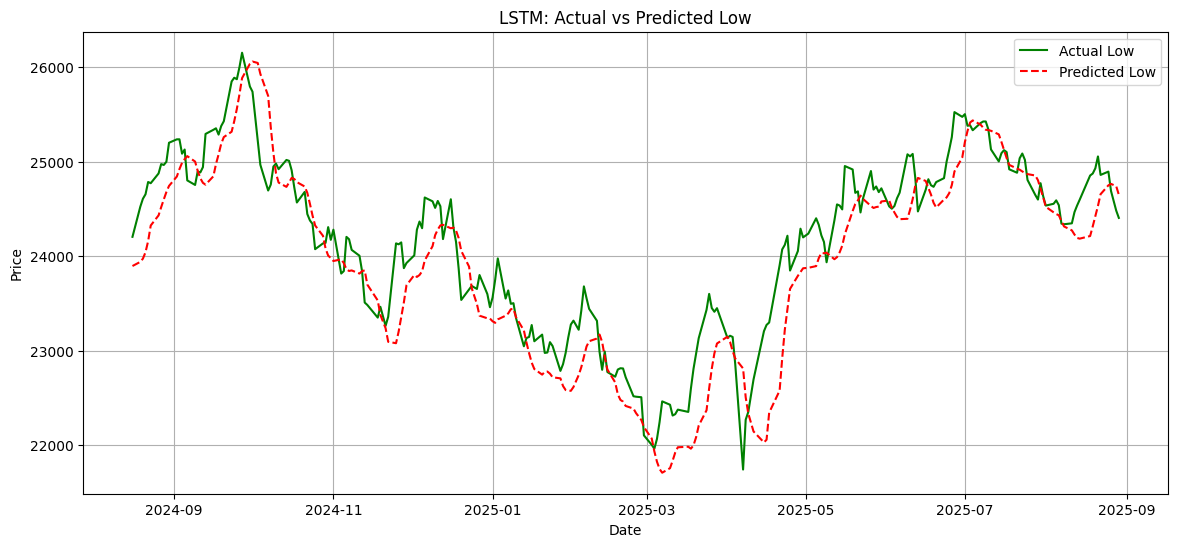

In [20]:
features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y_high = df['High'].values
y_low = df['Low'].values

# Scaling
scaler_X = MinMaxScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(df[['High','Low']].values)

# ------------------ CREATE SEQUENCES ------------------
def create_seq(X, y, seq_len=5):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 5
X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# Corresponding dates for test set
test_dates = df['Date'].values[seq_len + split_idx:]

# ------------------ LSTM MODEL ------------------
model = Sequential([
    LSTM(50, activation='relu', input_shape=(seq_len, X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(2)  # Predict High and Low
])
model.compile(optimizer='adam', loss='mse')

# Train
history = model.fit(
    X_train, y_train,
    epochs=25, batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)

# ------------------ PREDICT ------------------
pred = model.predict(X_test)
pred_inv = scaler_y.inverse_transform(pred)
y_test_inv = scaler_y.inverse_transform(y_test)

pred_high, pred_low = pred_inv[:,0], pred_inv[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, pred_high, "High (LSTM)")
metrics(y_low_true, pred_low, "Low (LSTM)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(test_dates, y_high_true, label="Actual High")
plt.plot(test_dates, pred_high, label="Predicted High", linestyle='--')
plt.title("LSTM: Actual vs Predicted High")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(test_dates, y_low_true, label="Actual Low", color='green')
plt.plot(test_dates, pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("LSTM: Actual vs Predicted Low")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend(); plt.grid(True); plt.show()

Epoch 1/25


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


146/146 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1075 - val_loss: 0.0229
Epoch 2/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0237 - val_loss: 0.0072
Epoch 3/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0200 - val_loss: 0.0086
Epoch 4/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0173 - val_loss: 0.0096
Epoch 5/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0162 - val_loss: 0.0129
Epoch 6/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0146 - val_loss: 0.0045
Epoch 7/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0155 - val_loss: 0.0168
Epoch 8/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0142 - val_loss: 0.0116
Epoch 9/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0140 - val_loss: 0.0081
Epoch 10/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0131 - val_loss: 0.0046
Epoch 11/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0137 - val_loss: 0.0190
Epoch 12/25
146/146 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.

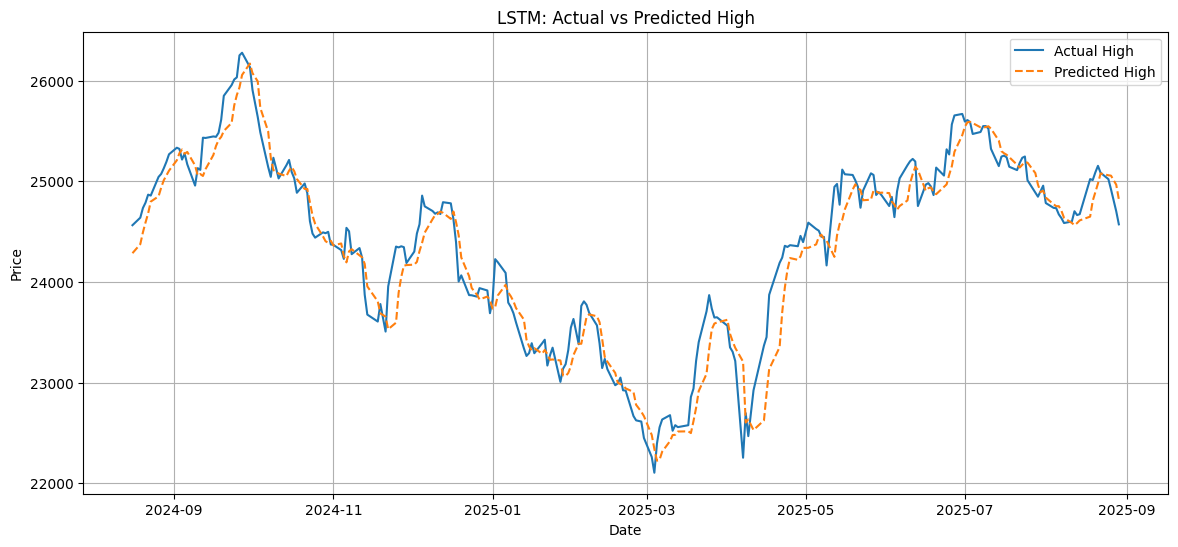

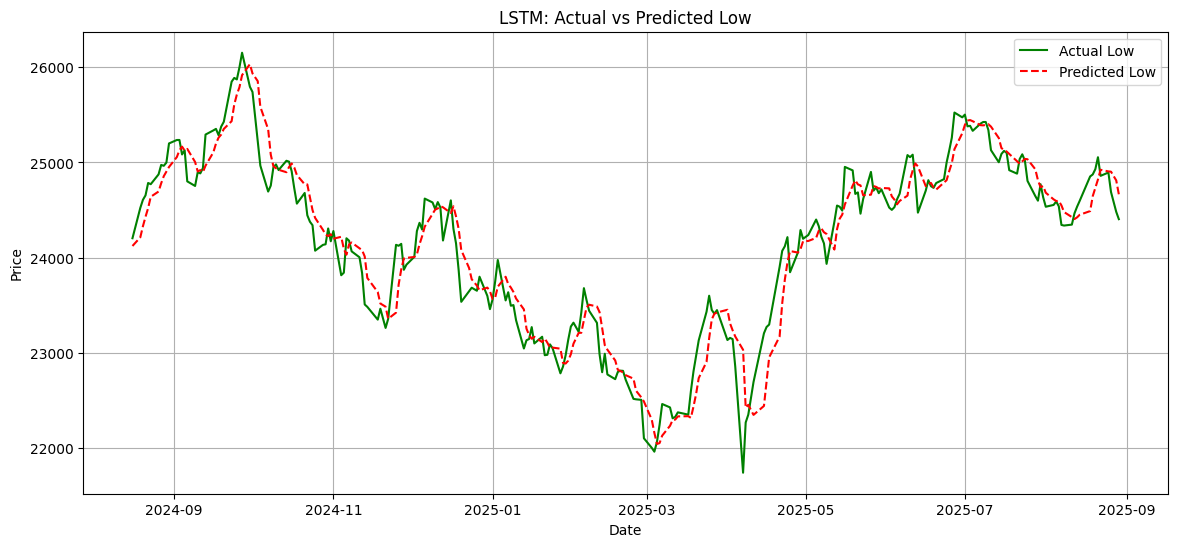

In [21]:
features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y_high = df['High'].values
y_low = df['Low'].values

# Scaling
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(df[['High','Low']].values)

# ------------------ CREATE SEQUENCES ------------------
def create_seq(X, y, seq_len=5):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 5
X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# Corresponding dates for test set
test_dates = df['Date'].values[seq_len + split_idx:]

# ------------------ LSTM MODEL ------------------
model = Sequential([
    LSTM(50, activation='relu', input_shape=(seq_len, X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(2)  # Predict High and Low
])
model.compile(optimizer='adam', loss='mse')

# Train
history = model.fit(
    X_train, y_train,
    epochs=25, batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)

# ------------------ PREDICT ------------------
pred = model.predict(X_test)
pred_inv = scaler_y.inverse_transform(pred)
y_test_inv = scaler_y.inverse_transform(y_test)

pred_high, pred_low = pred_inv[:,0], pred_inv[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, pred_high, "High (LSTM)")
metrics(y_low_true, pred_low, "Low (LSTM)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(test_dates, y_high_true, label="Actual High")
plt.plot(test_dates, pred_high, label="Predicted High", linestyle='--')
plt.title("LSTM: Actual vs Predicted High")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(test_dates, y_low_true, label="Actual Low", color='green')
plt.plot(test_dates, pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("LSTM: Actual vs Predicted Low")
plt.xlabel("Date")
plt.ylabel("Price")
plt.legend(); plt.grid(True); plt.show()

Epoch 1/25


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


147/147 ━━━━━━━━━━━━━━━━━━━━ 1s 3ms/step - loss: 0.1388 - val_loss: 0.0837
Epoch 2/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0245 - val_loss: 0.0092
Epoch 3/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0190 - val_loss: 0.0084
Epoch 4/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0191 - val_loss: 0.0050
Epoch 5/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0164 - val_loss: 0.0040
Epoch 6/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0153 - val_loss: 0.0074
Epoch 7/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0155 - val_loss: 0.0075
Epoch 8/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0143 - val_loss: 0.0337
Epoch 9/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0147 - val_loss: 0.0093
Epoch 10/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 1ms/step - loss: 0.0134 - val_loss: 0.0209
Epoch 11/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.0139 - val_loss: 0.0047
Epoch 12/25
147/147 ━━━━━━━━━━━━━━━━━━━━ 0s 2ms/step - loss: 0.

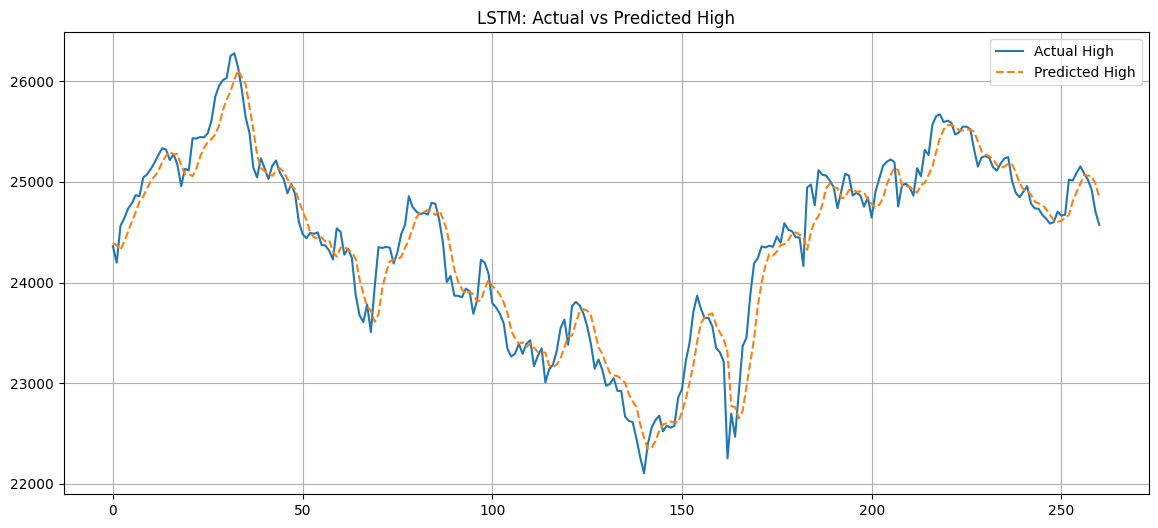

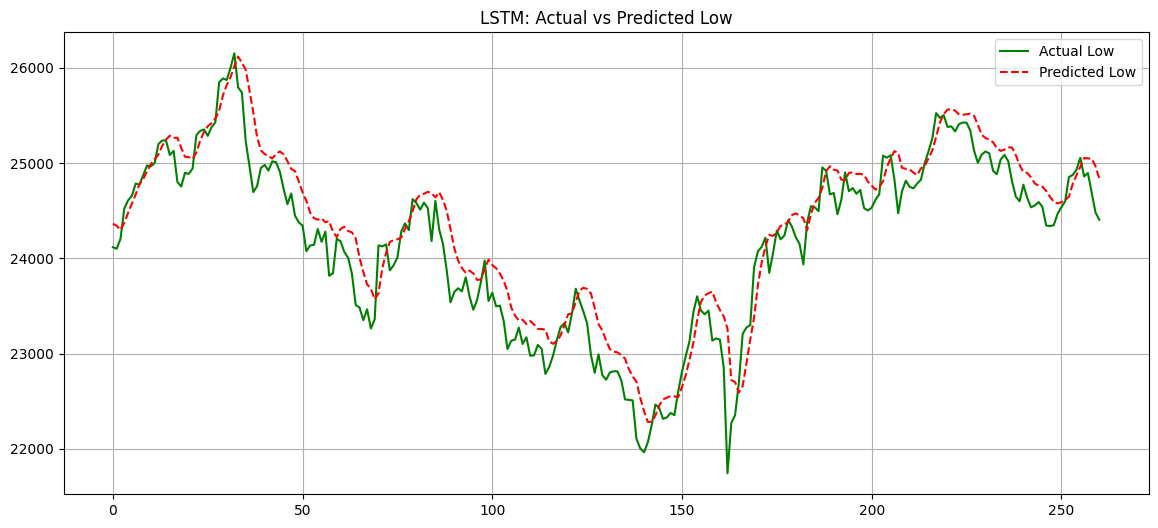

In [11]:
#for sequence length 50
features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y_high = df['High'].values
y_low = df['Low'].values

# Scaling
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(df[['High','Low']].values)

# ------------------ CREATE SEQUENCES ------------------
def create_seq(X, y, seq_len=5):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 5
X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# ------------------ LSTM MODEL ------------------
model = Sequential([
    LSTM(50, activation='relu', input_shape=(seq_len, X_train.shape[2]), return_sequences=False),
    Dropout(0.2),
    Dense(2)
])
model.compile(optimizer='adam', loss='mse')

# Train
history = model.fit(X_train, y_train, epochs=25, batch_size=16, validation_data=(X_test, y_test), verbose=1)

# Predict
pred = model.predict(X_test)
pred_inv = scaler_y.inverse_transform(pred)
y_test_inv = scaler_y.inverse_transform(y_test)

pred_high, pred_low = pred_inv[:,0], pred_inv[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, pred_high, "High (LSTM)")
metrics(y_low_true, pred_low, "Low (LSTM)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High")
plt.plot(pred_high, label="Predicted High", linestyle='--')
plt.title("LSTM: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true, label="Actual Low", color='green')
plt.plot(pred_low, label="Predicted Low", linestyle='--', color='red')
plt.title("LSTM: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()

In [12]:
from tcn import TCN

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tcn (TCN)                       │ (None, 64)             │        87,616 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 50)             │         3,250 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 50)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 2)              │           102 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 90,968 (355.34 KB)

 Trainable params: 90,968 (355.34 KB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/30
145/145 ━━━━━━━━━━━━━━━━━━━━ 3s 8ms/step - loss: 3.1110 - val_loss: 0.3512
Epoch 2/30
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.2352 - val_loss: 0.2984
Epoch 3/30
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1441 - val_loss: 0.1860
Epoch 4/30
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.1251 - val_loss: 0.1074
Epoch 5/30
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0946 - val_loss: 0.1135
Epoch 6/30
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0852 - val_loss: 0.1073
Epoch 7/30
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0737 - val_loss: 0.1213
Epoch 8/30
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0646 - val_loss: 0.1245
Epoch 9/30
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0547 - val_loss: 0.1297
Epoch 10/30
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0528 - val_loss: 0.1079
Epoch 11/30
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step - loss: 0.0443 - val_loss: 0.1515
Epoch 12/30
145/145 ━━━━━━━━━━━━━━━━━━━━ 1s 6ms/step

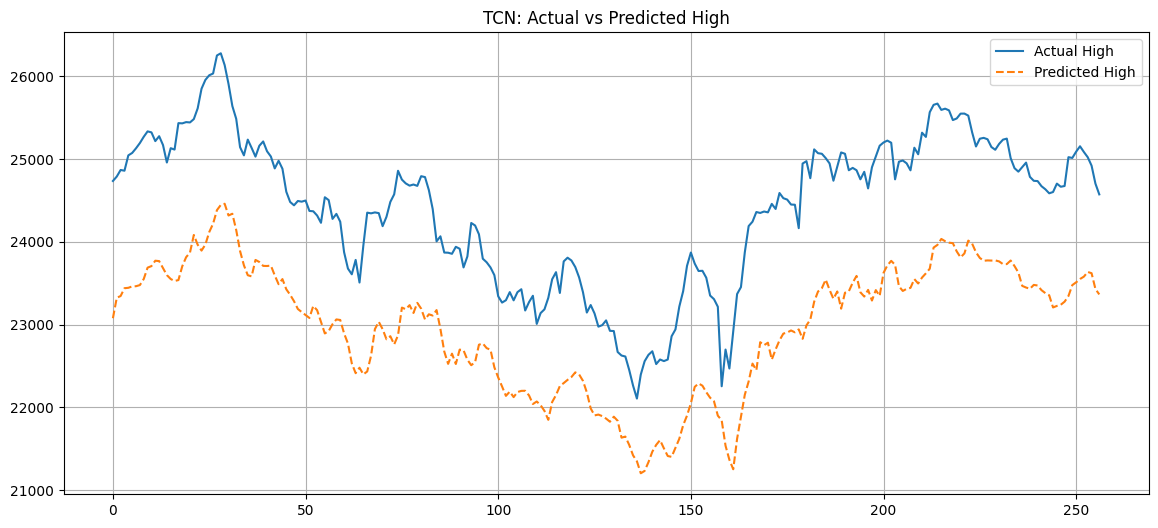

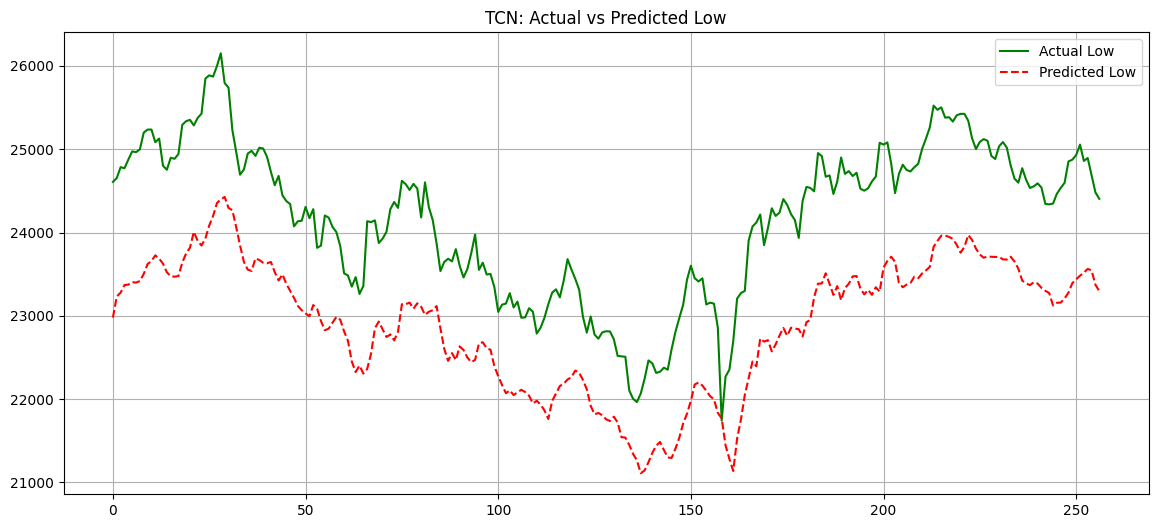

In [13]:





features = ['Open', 'Close', 'High', 'Low']
X = df[features].values
y = df[['High','Low']].values

# ------------------ SCALING ------------------
scaler_X = StandardScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = StandardScaler()
y_scaled = scaler_y.fit_transform(y)

# ------------------ CREATE SEQUENCES ------------------
def create_sequences(X, y, seq_len=50):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 50  # Hyperparameter: sequence length
X_seq, y_seq = create_sequences(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# ------------------ BUILD TCN MODEL ------------------
model = Sequential([
    TCN(input_shape=(seq_len, X_train.shape[2]), 
        nb_filters=64,       # Number of convolutional filters
        kernel_size=3,       # Filter/kernel size
        dilations=[1,2,4,8],# Dilation factors for receptive field
        dropout_rate=0.2,    # Dropout for regularization
        return_sequences=False),
    Dense(50, activation='relu'),
    Dropout(0.2),
    Dense(2)  # Predict High and Low
])

model.compile(optimizer='adam', loss='mse')
model.summary()

# ------------------ TRAIN ------------------
history = model.fit(
    X_train, y_train,
    epochs=30, batch_size=16,
    validation_data=(X_test, y_test),
    verbose=1
)

# ------------------ PREDICT ------------------
y_pred_scaled = model.predict(X_test)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_test_inv = scaler_y.inverse_transform(y_test)

y_high_pred, y_low_pred = y_pred[:,0], y_pred[:,1]
y_high_true, y_low_true = y_test_inv[:,0], y_test_inv[:,1]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true, y_high_pred, "High (TCN)")
metrics(y_low_true, y_low_pred, "Low (TCN)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true, label="Actual High")
plt.plot(y_high_pred, label="Predicted High", linestyle='--')
plt.title("TCN: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true, label="Actual Low", color='green')
plt.plot(y_low_pred, label="Predicted Low", linestyle='--', color='red')
plt.title("TCN: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()


In [16]:
from sklearn.preprocessing import MinMaxScaler

d:\Anacondaa\envs\tfenv\lib\site-packages\tcn\tcn.py:268: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super(TCN, self).__init__(**kwargs)


Model: "sequential_4"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ tcn_1 (TCN)                     │ (None, 128)            │       464,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 64)             │         8,256 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 64)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 2)              │           130 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 472,642 (1.80 MB)

 Trainable params: 472,642 (1.80 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 4s 22ms/step - loss: 2.2041 - val_loss: 0.0585
Epoch 2/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0701 - val_loss: 0.0604
Epoch 3/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0449 - val_loss: 0.0381
Epoch 4/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0358 - val_loss: 0.0277
Epoch 5/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0292 - val_loss: 0.0235
Epoch 6/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0254 - val_loss: 0.0210
Epoch 7/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0237 - val_loss: 0.0193
Epoch 8/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0212 - val_loss: 0.0113
Epoch 9/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 20ms/step - loss: 0.0202 - val_loss: 0.0088
Epoch 10/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0193 - val_loss: 0.0244
Epoch 11/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0179 - val_loss: 0.0155
Epoch 12/50
72/72 ━━━━━━━━━━━━━━━━━━━━ 1s 19ms/step - loss: 0.0

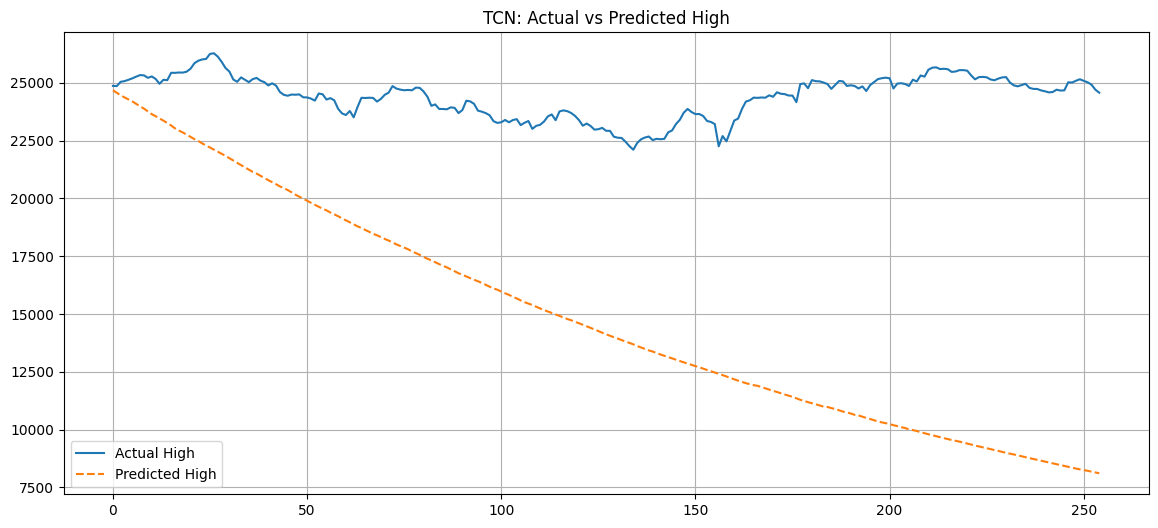

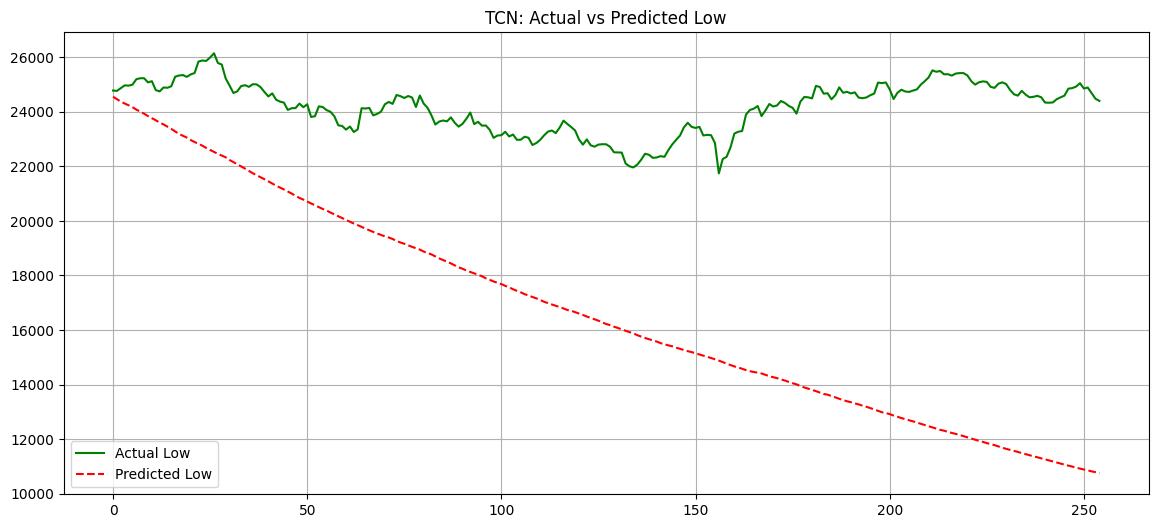

In [17]:


# Create percentage change features (returns)
df['Open_ret'] = df['Open'].pct_change()
df['High_ret'] = df['High'].pct_change()
df['Low_ret'] = df['Low'].pct_change()
df['Close_ret'] = df['Close'].pct_change()

# Drop first row (NaN due to pct_change)
df = df.dropna().reset_index(drop=True)

# Create lag features
lags = 5
for col in ['Open_ret','High_ret','Low_ret','Close_ret']:
    for lag in range(1, lags+1):
        df[f'{col}_lag{lag}'] = df[col].shift(lag)

df = df.dropna().reset_index(drop=True)

# Define features and targets
features = [c for c in df.columns if 'lag' in c]
X = df[features].values
y = df[['High_ret','Low_ret']].values  # Predict next-day returns

# ------------------ SCALING ------------------
scaler_X = MinMaxScaler()
X_scaled = scaler_X.fit_transform(X)

scaler_y = MinMaxScaler()
y_scaled = scaler_y.fit_transform(y)

# ------------------ CREATE SEQUENCES ------------------
def create_sequences(X, y, seq_len=50):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)

seq_len = 50
X_seq, y_seq = create_sequences(X_scaled, y_scaled, seq_len)

# Train-test split
split_idx = int(len(X_seq)*0.9)
X_train, X_test = X_seq[:split_idx], X_seq[split_idx:]
y_train, y_test = y_seq[:split_idx], y_seq[split_idx:]

# ------------------ BUILD TCN MODEL ------------------
model = Sequential([
    TCN(input_shape=(seq_len, X_train.shape[2]), 
        nb_filters=128,
        kernel_size=3,
        dilations=[1,2,4,8,16],
        dropout_rate=0.2,
        return_sequences=False),
    Dense(64, activation='relu'),
    Dropout(0.2),
    Dense(2)  # Predict High & Low returns
])

model.compile(optimizer='adam', loss='mse')
model.summary()

# ------------------ TRAIN ------------------
history = model.fit(
    X_train, y_train,
    epochs=50, batch_size=32,
    validation_data=(X_test, y_test),
    verbose=1
)

# ------------------ PREDICT ------------------
y_pred_scaled = model.predict(X_test)
y_pred = scaler_y.inverse_transform(y_pred_scaled)
y_test_inv = scaler_y.inverse_transform(y_test)

# Convert predicted returns back to price
last_high = df['High'].values[split_idx + seq_len - 1]
last_low = df['Low'].values[split_idx + seq_len - 1]

y_high_pred_prices = [last_high*(1 + y_pred[0,0])]
y_low_pred_prices  = [last_low*(1 + y_pred[0,1])]

for i in range(1, len(y_pred)):
    y_high_pred_prices.append(y_high_pred_prices[-1]*(1 + y_pred[i,0]))
    y_low_pred_prices.append(y_low_pred_prices[-1]*(1 + y_pred[i,1]))

y_high_true_prices = df['High'].values[split_idx + seq_len:]
y_low_true_prices  = df['Low'].values[split_idx + seq_len:]

# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100
    print(f"\n📊 {label} Metrics:")
    print(f"MAE  : {mae:.3f}")
    print(f"RMSE : {rmse:.3f}")
    print(f"R²   : {r2:.3f}")
    print(f"MAPE : {mape:.2f}%")
    return mae, rmse, r2, mape

metrics(y_high_true_prices, y_high_pred_prices, "High (TCN)")
metrics(y_low_true_prices, y_low_pred_prices, "Low (TCN)")

# ------------------ PLOTS ------------------
plt.figure(figsize=(14,6))
plt.plot(y_high_true_prices, label="Actual High")
plt.plot(y_high_pred_prices, label="Predicted High", linestyle='--')
plt.title("TCN: Actual vs Predicted High")
plt.legend(); plt.grid(True); plt.show()

plt.figure(figsize=(14,6))
plt.plot(y_low_true_prices, label="Actual Low", color='green')
plt.plot(y_low_pred_prices, label="Predicted Low", linestyle='--', color='red')
plt.title("TCN: Actual vs Predicted Low")
plt.legend(); plt.grid(True); plt.show()



==================== LSTM for Segment: 2007-2010 ====================

Epoch 1/60


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


112/112 ━━━━━━━━━━━━━━━━━━━━ 3s 11ms/step - loss: 0.0831 - val_loss: 0.0202 - learning_rate: 0.0010
Epoch 2/60
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0203 - val_loss: 0.0155 - learning_rate: 0.0010
Epoch 3/60
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 8ms/step - loss: 0.0172 - val_loss: 0.0687 - learning_rate: 0.0010
Epoch 4/60
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0181 - val_loss: 0.0138 - learning_rate: 0.0010
Epoch 5/60
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0130 - val_loss: 0.0100 - learning_rate: 0.0010
Epoch 6/60
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0131 - val_loss: 0.0217 - learning_rate: 0.0010
Epoch 7/60
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0123 - val_loss: 0.0156 - learning_rate: 0.0010
Epoch 8/60
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0113 - val_loss: 0.0113 - learning_rate: 0.0010
Epoch 9/60
112/112 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - loss: 0.0159 - val_loss: 0.0462 - learning_rate: 0.0010
Epoch 10/60
112/112 

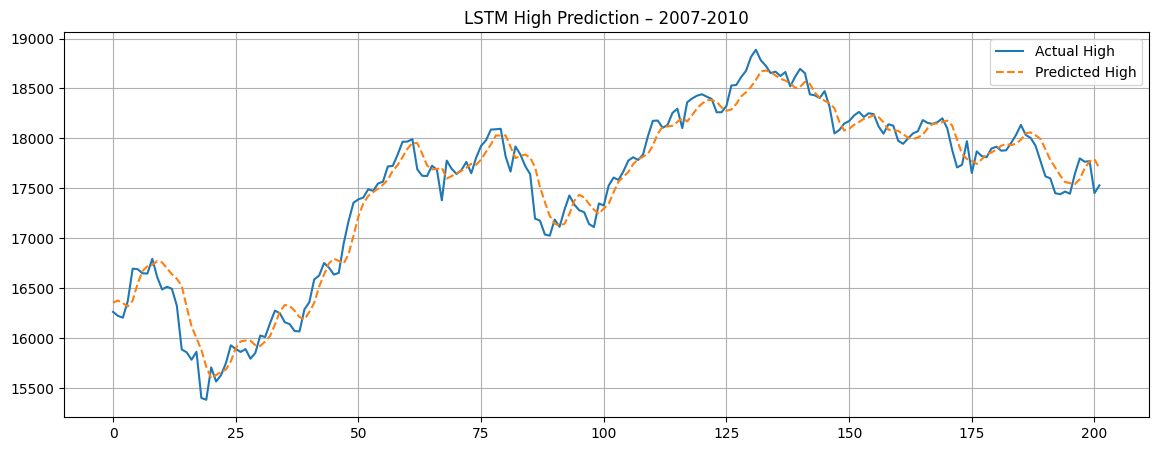

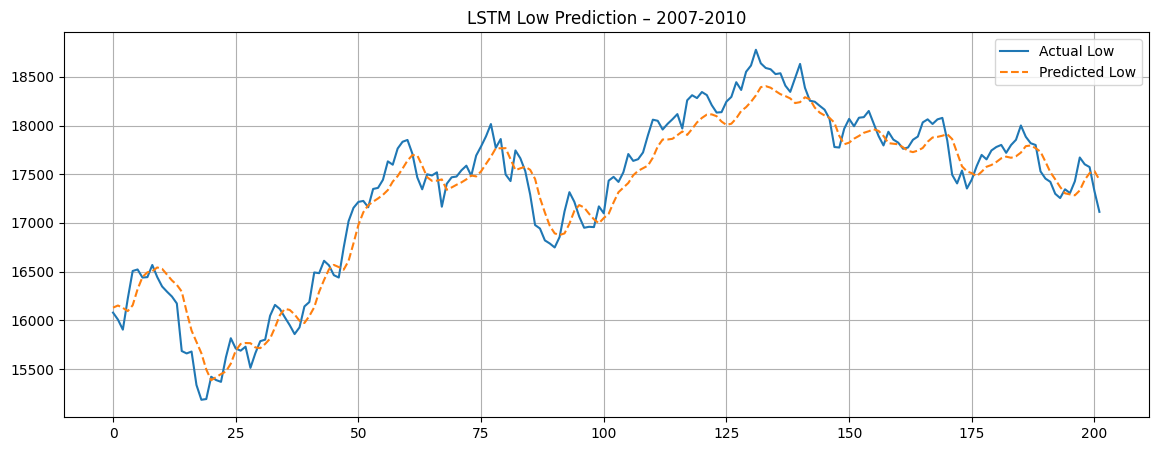


==================== LSTM for Segment: 2011-2019 ====================

Segment too small. Skipping.

==================== LSTM for Segment: 2020-2021 ====================

Segment too small. Skipping.

==================== LSTM for Segment: 2022-End ====================

Epoch 1/60


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


33/33 ━━━━━━━━━━━━━━━━━━━━ 2s 18ms/step - loss: 0.1686 - val_loss: 0.0177 - learning_rate: 0.0010
Epoch 2/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0418 - val_loss: 0.0139 - learning_rate: 0.0010
Epoch 3/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0360 - val_loss: 0.0112 - learning_rate: 0.0010
Epoch 4/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0351 - val_loss: 0.0110 - learning_rate: 0.0010
Epoch 5/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0291 - val_loss: 0.0100 - learning_rate: 0.0010
Epoch 6/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0289 - val_loss: 0.0098 - learning_rate: 0.0010
Epoch 7/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0265 - val_loss: 0.0224 - learning_rate: 0.0010
Epoch 8/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0274 - val_loss: 0.0271 - learning_rate: 0.0010
Epoch 9/60
33/33 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0257 - val_loss: 0.0091 - learning_rate: 0.0010
Epoch 10/60
33/33 ━━━━━━━━━━━━

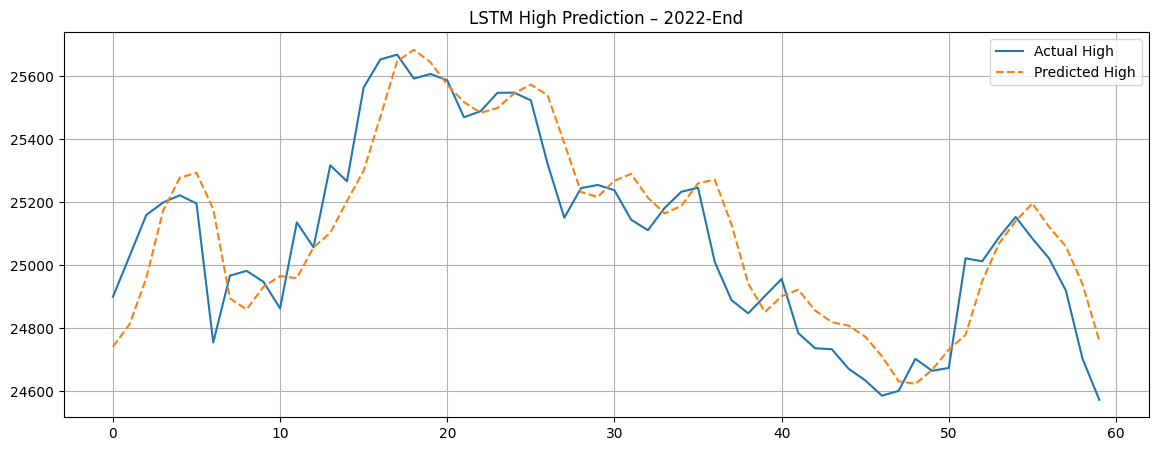

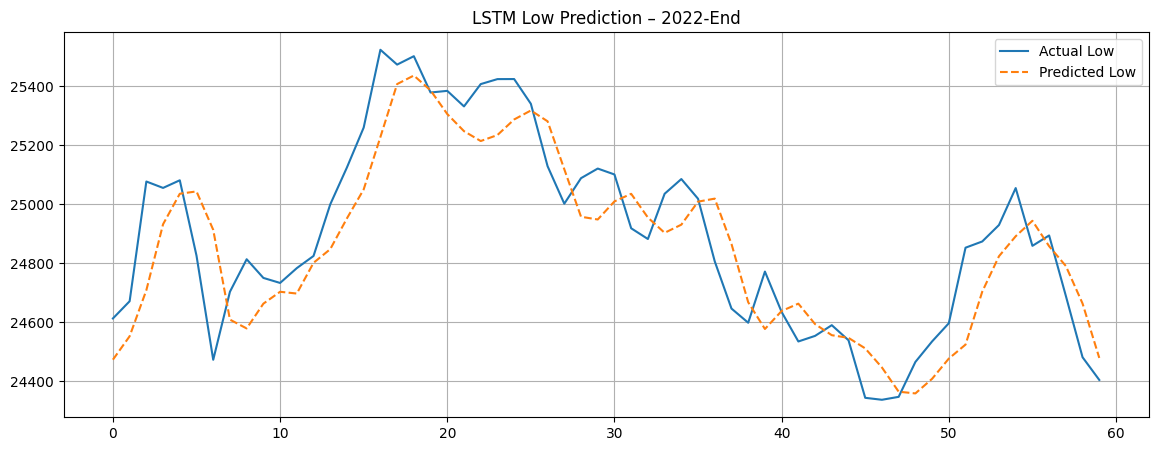

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# ------------------ DATA SEGMENTS ------------------
def split_segments(df):
    return {
        "2007-2010": df.loc[:'2010'],
        "2011-2019": df.loc['2011':'2019'],
        "2020-2021": df.loc['2020':'2021'],
        "2022-End": df.loc['2022':]
    }


# ------------------ SEQUENCE CREATION ------------------
def create_seq(X, y, seq_len=20):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)


# ------------------ METRICS ------------------
def metrics(y_true, y_pred, label):
    mae = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2 = r2_score(y_true, y_pred)
    mape = np.mean(np.abs((y_true - y_pred) / y_true)) * 100

    print(f"\n==== {label} ====")
    print(f"MAE   : {mae:.3f}")
    print(f"RMSE  : {rmse:.3f}")
    print(f"R²    : {r2:.3f}")
    print(f"MAPE  : {mape:.2f}%")

    return mae, rmse, r2, mape


# ------------------ BUILD BEST LSTM ------------------
def build_lstm(input_shape):
    model = Sequential([
        LSTM(96, return_sequences=True, activation='tanh', input_shape=input_shape),
        Dropout(0.2),

        LSTM(64, return_sequences=False, activation='tanh'),
        Dropout(0.2),

        Dense(32, activation='relu'),
        Dense(2)
    ])

    model.compile(optimizer='adam', loss='mse')
    return model


# ------------------ MAIN PIPELINE PER SEGMENT ------------------
def run_lstm_segment(df_segment, name):

    print(f"\n==================== LSTM for Segment: {name} ====================\n")

    if len(df_segment) < 50:
        print("Segment too small. Skipping.")
        return None

    features = ['Open', 'Close', 'High', 'Low']

    X = df_segment[features].values
    y = df_segment[['High', 'Low']].values

    seq_len = 20


    # ----- Train-test split -----
    split_idx = int(len(X) * 0.9)
    X_train_raw, X_test_raw = X[:split_idx], X[split_idx:]
    y_train_raw, y_test_raw = y[:split_idx], y[split_idx:]


    # ----- Scale using only train -----
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled = scaler_y.transform(y_test_raw)

    # ----- Recombine after scaling -----
    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])


    # ----- Create sequences -----
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    # Align train-test again after window shift
    final_split = len(X_train_raw) - seq_len
    X_train, X_test = X_seq[:final_split], X_seq[final_split:]
    y_train, y_test = y_seq[:final_split], y_seq[final_split:]


    # ----- LSTM MODEL -----
    model = build_lstm((seq_len, X_train.shape[2]))

    es = EarlyStopping(monitor='val_loss', patience=7, restore_best_weights=True)
    lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=4)

    history = model.fit(
        X_train, y_train,
        epochs=60,
        batch_size=16,
        validation_data=(X_test, y_test),
        callbacks=[es, lr],
        verbose=1
    )


    # ----- Predict -----
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:, 0], pred[:, 1]
    true_high, true_low = y_true[:, 0], y_true[:, 1]


    # ----- Metrics -----
    metrics(true_high, pred_high, f"{name} High")
    metrics(true_low, pred_low, f"{name} Low")


    # ----- PLOTS -----
    plt.figure(figsize=(14,5))
    plt.plot(true_high, label="Actual High")
    plt.plot(pred_high, label="Predicted High", linestyle='--')
    plt.title(f"LSTM High Prediction – {name}")
    plt.legend()
    plt.grid(True)
    plt.show()

    plt.figure(figsize=(14,5))
    plt.plot(true_low, label="Actual Low")
    plt.plot(pred_low, label="Predicted Low", linestyle='--')
    plt.title(f"LSTM Low Prediction – {name}")
    plt.legend()
    plt.grid(True)
    plt.show()

    return pred, y_true



# ------------------ LOAD + RUN EVERYTHING ------------------


segments = split_segments(df)

results = {}
for name, seg in segments.items():
    results[name] = run_lstm_segment(seg, name)


In [16]:
import yfinance as yf
import pandas as pd

# Download NIFTY 50 (^NSEI) from 2007 to now
nifty = yf.download("^NSEI", start="2007-01-01", end=None)

# Save to CSV if needed
nifty.to_csv("nifty50_2007_to_now.csv")

print(nifty.head())
print(nifty.tail())


C:\Users\ASUS\AppData\Local\Temp\ipykernel_75564\3753563862.py:5: FutureWarning: YF.download() has changed argument auto_adjust default to True
  nifty = yf.download("^NSEI", start="2007-01-01", end=None)
[*********************100%***********************]  1 of 1 completed

Price             Close         High          Low         Open Volume
Ticker            ^NSEI        ^NSEI        ^NSEI        ^NSEI  ^NSEI
Date                                                                 
2007-09-17  4494.649902  4549.049805  4482.850098  4518.450195      0
2007-09-18  4546.200195  4551.799805  4481.549805  4494.100098      0
2007-09-19  4732.350098  4739.000000  4550.250000  4550.250000      0
2007-09-20  4747.549805  4760.850098  4721.149902  4734.850098      0
2007-09-21  4837.549805  4855.700195  4733.700195  4752.950195      0
Price              Close          High           Low          Open  Volume
Ticker             ^NSEI         ^NSEI         ^NSEI         ^NSEI   ^NSEI
Date                                                                      
2025-11-19  26052.650391  26074.650391  25856.199219  25918.099609  250100
2025-11-20  26192.150391  26246.650391  26063.199219  26132.099609  240400
2025-11-21  26068.150391  26179.199219  26052.199219  26109.55078

In [20]:
df = df.drop([1, 2]).reset_index(drop=True)

# Optional: verify
print(df.head(5))
# Assuming your DataFrame is named df
df = df.drop(index=0).reset_index(drop=True)

# Optional: confirm it worked
print(df.head())
df.columns = ['Date', 'Open', 'High', 'Low', 'Close', 'Volume']  # rename manually
for col in df.columns:
    if col != 'Date':
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Optional: fill missing values created by coercion
df = df.fillna(method='ffill').fillna(method='bfill')

# Confirm that everything is now numeric
print(df.dtypes)

         Date              Open              High               Low  \
0  2007-09-18   4546.2001953125   4551.7998046875   4481.5498046875   
1  2007-09-21   4837.5498046875   4855.7001953125   4733.7001953125   
2  2007-09-24   4932.2001953125  4941.14990234375  4837.14990234375   
3  2007-09-25  4938.85009765625  4953.89990234375  4878.14990234375   
4  2007-09-26            4940.5  4980.85009765625  4930.35009765625   

              Close Volume  
0  4494.10009765625      0  
1   4752.9501953125      0  
2  4837.14990234375      0  
3  4939.10009765625      0  
4  4937.60009765625      0  
         Date              Open              High               Low  \
0  2007-09-21   4837.5498046875   4855.7001953125   4733.7001953125   
1  2007-09-24   4932.2001953125  4941.14990234375  4837.14990234375   
2  2007-09-25  4938.85009765625  4953.89990234375  4878.14990234375   
3  2007-09-26            4940.5  4980.85009765625  4930.35009765625   
4  2007-09-27   5000.5498046875  5016.399902

C:\Users\ASUS\AppData\Local\Temp\ipykernel_75564\1660615690.py:16: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='ffill').fillna(method='bfill')


In [27]:
# Load dataset
df= pd.read_csv('nifty50_2007_to_now.csv')
df = df.drop([1, 2]).reset_index(drop=True)

# Optional: verify
# Assuming your DataFrame is named df
df = df.drop(index=0).reset_index(drop=True)

# Optional: confirm it worked

df.columns = ['Date', 'Open', 'High', 'Low', 'Close', 'Volume']  # rename manually
for col in df.columns:
    if col != 'Date':
        df[col] = pd.to_numeric(df[col], errors='coerce')

# Optional: fill missing values created by coercion
df = df.fillna(method='ffill').fillna(method='bfill')
print(df.head())

# Confirm that everything is now numeric
print(df.dtypes)
# Create separate datasets
df1 = df['Date'].loc[:'2010-12-31']
df2 = df.loc['2011-01-01':'2019-12-31']
df3 = df.loc['2020-01-01':'2021-12-31']
df4 = df.loc['2022-01-01':]

print("Sizes of each segment:")
print("df1 (till 2010):", len(df1))
print("df2 (2011-2019):", len(df2))
print("df3 (2020-2021):", len(df3))
print("df4 (2022-end):", len(df4))


         Date         Open         High          Low        Close  Volume
0  2007-09-18  4546.200195  4551.799805  4481.549805  4494.100098       0
1  2007-09-19  4732.350098  4739.000000  4550.250000  4550.250000       0
2  2007-09-20  4747.549805  4760.850098  4721.149902  4734.850098       0
3  2007-09-21  4837.549805  4855.700195  4733.700195  4752.950195       0
4  2007-09-24  4932.200195  4941.149902  4837.149902  4837.149902       0
Date       object
Open      float64
High      float64
Low       float64
Close     float64
Volume      int64
dtype: object
Sizes of each segment:
df1 (till 2010): 2011
df2 (2011-2019): 8
df3 (2020-2021): 1
df4 (2022-end): 2438


C:\Users\ASUS\AppData\Local\Temp\ipykernel_75564\944123772.py:17: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df = df.fillna(method='ffill').fillna(method='bfill')


In [28]:
# Convert Date column to datetime
df['Date'] = pd.to_datetime(df['Date'])

# Set Date as index
df = df.set_index('Date')

# Now your slicing will work perfectly
df1 = df.loc[:'2010-12-31']
df2 = df.loc['2011-01-01':'2019-12-31']
df3 = df.loc['2020-01-01':'2021-12-31']
df4 = df.loc['2022-01-01':]

print("df1:", df1.shape)
print("df2:", df2.shape)
print("df3:", df3.shape)
print("df4:", df4.shape)


df1: (807, 5)
df2: (2193, 5)
df3: (498, 5)
df4: (963, 5)


In [29]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau


# ---------------- SEQUENCE CREATION ----------------
def create_seq(X, y, seq_len=25):
    X_seq, y_seq = [], []
    for i in range(seq_len, len(X)):
        X_seq.append(X[i-seq_len:i])
        y_seq.append(y[i])
    return np.array(X_seq), np.array(y_seq)


# ---------------- METRICS ----------------
def metrics(y_true, y_pred, label):
    mae  = mean_absolute_error(y_true, y_pred)
    rmse = np.sqrt(mean_squared_error(y_true, y_pred))
    r2   = r2_score(y_true,  y_pred)
    mape = np.mean(np.abs((y_true - y_pred)/y_true))*100

    print(f"\n===== {label} =====")
    print("MAE :",  round(mae,3))
    print("RMSE:",  round(rmse,3))
    print("R2  :",  round(r2,3))
    print("MAPE:", round(mape,2), "%")

    return mae, rmse, r2, mape


# ---------------- BUILD LSTM MODEL ----------------
def build_lstm(input_shape):
    model = Sequential([
        LSTM(96, return_sequences=True, input_shape=input_shape),
        Dropout(0.25),

        LSTM(64, return_sequences=False),
        Dropout(0.25),

        Dense(32, activation='relu'),
        Dense(2)
    ])
    model.compile(optimizer='adam', loss='mse')
    return model


# ---------------- MAIN FUNCTION ----------------
def run_LSTM(df, name):

    print(f"\n================ LSTM for {name} ================")

    # Features and target
    X = df[['Open','High','Low','Close']].values
    y = df[['High','Low']].values

    seq_len = 25
    train_size = max(int(len(df)*0.85), seq_len+3)
    train_size = min(train_size, len(df)-2)

    X_train_raw = X[:train_size]
    X_test_raw  = X[train_size:]

    y_train_raw = y[:train_size]
    y_test_raw  = y[train_size:]

    # Scaling
    scaler_X = StandardScaler()
    scaler_y = StandardScaler()

    X_train_scaled = scaler_X.fit_transform(X_train_raw)
    X_test_scaled  = scaler_X.transform(X_test_raw)

    y_train_scaled = scaler_y.fit_transform(y_train_raw)
    y_test_scaled  = scaler_y.transform(y_test_raw)

    X_scaled = np.vstack([X_train_scaled, X_test_scaled])
    y_scaled = np.vstack([y_train_scaled, y_test_scaled])

    # Sequence creation
    X_seq, y_seq = create_seq(X_scaled, y_scaled, seq_len)

    split = train_size - seq_len
    X_train, X_test = X_seq[:split], X_seq[split:]
    y_train, y_test = y_seq[:split], y_seq[split:]

    # Adaptive batch size
    batch = 16 if len(X_train)>50 else 4

    model = build_lstm((seq_len, X_train.shape[2]))

    es = EarlyStopping(patience=6, restore_best_weights=True)
    lr = ReduceLROnPlateau(factor=0.5, patience=3)

    model.fit(
        X_train, y_train,
        epochs=60,
        batch_size=batch,
        validation_data=(X_test, y_test) if len(X_test)>1 else None,
        callbacks=[es, lr],
        verbose=1
    )

    # Prediction
    pred_scaled = model.predict(X_test)
    pred = scaler_y.inverse_transform(pred_scaled)
    y_true = scaler_y.inverse_transform(y_test)

    pred_high, pred_low = pred[:,0], pred[:,1]
    true_high, true_low = y_true[:,0], y_true[:,1]

    m1 = metrics(true_high, pred_high, f"LSTM {name} High")
    m2 = metrics(true_low, pred_low, f"LSTM {name} Low")

    return (m1, m2)


In [30]:
results_lstm = {}

results_lstm['df1'] = run_LSTM(df1, "2007–2010")
results_lstm['df2'] = run_LSTM(df2, "2011–2019")
results_lstm['df3'] = run_LSTM(df3, "2020–2021")
results_lstm['df4'] = run_LSTM(df4, "2022–Now")



================ LSTM for 2007–2010 ================


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Epoch 1/60
42/42 ━━━━━━━━━━━━━━━━━━━━ 3s 20ms/step - loss: 0.1656 - val_loss: 0.1623 - learning_rate: 0.0010
Epoch 2/60
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 13ms/step - loss: 0.0621 - val_loss: 0.0313 - learning_rate: 0.0010
Epoch 3/60
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0617 - val_loss: 0.0114 - learning_rate: 0.0010
Epoch 4/60
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0503 - val_loss: 0.0410 - learning_rate: 0.0010
Epoch 5/60
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0432 - val_loss: 0.0260 - learning_rate: 0.0010
Epoch 6/60
42/42 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0404 - val_loss: 0.0479 - learning_rate: 0.0010
Epoch 7/60
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0382 - val_loss: 0.0108 - learning_rate: 5.0000e-04
Epoch 8/60
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0361 - val_loss: 0.0088 - learning_rate: 5.0000e-04
Epoch 9/60
42/42 ━━━━━━━━━━━━━━━━━━━━ 1s 12ms/step - loss: 0.0366 - val_loss: 0.0128 - learning_rate: 5.0000e-04
Epoch 1

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


115/115 ━━━━━━━━━━━━━━━━━━━━ 3s 12ms/step - loss: 0.0768 - val_loss: 0.0564 - learning_rate: 0.0010
Epoch 2/60
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0188 - val_loss: 0.0250 - learning_rate: 0.0010
Epoch 3/60
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0160 - val_loss: 0.0241 - learning_rate: 0.0010
Epoch 4/60
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0141 - val_loss: 0.0272 - learning_rate: 0.0010
Epoch 5/60
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0144 - val_loss: 0.0289 - learning_rate: 0.0010
Epoch 6/60
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0138 - val_loss: 0.0150 - learning_rate: 0.0010
Epoch 7/60
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0123 - val_loss: 0.0340 - learning_rate: 0.0010
Epoch 8/60
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0116 - val_loss: 0.0476 - learning_rate: 0.0010
Epoch 9/60
115/115 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step - loss: 0.0110 - val_loss: 0.0148 - learning_rate: 0.0010
Epoch 10/60


d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


25/25 ━━━━━━━━━━━━━━━━━━━━ 3s 23ms/step - loss: 0.3874 - val_loss: 0.7064 - learning_rate: 0.0010
Epoch 2/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0795 - val_loss: 0.1860 - learning_rate: 0.0010
Epoch 3/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0430 - val_loss: 0.0568 - learning_rate: 0.0010
Epoch 4/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0394 - val_loss: 0.0580 - learning_rate: 0.0010
Epoch 5/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0355 - val_loss: 0.0357 - learning_rate: 0.0010
Epoch 6/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0341 - val_loss: 0.0234 - learning_rate: 0.0010
Epoch 7/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0310 - val_loss: 0.0284 - learning_rate: 0.0010
Epoch 8/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0314 - val_loss: 0.0299 - learning_rate: 0.0010
Epoch 9/60
25/25 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0314 - val_loss: 0.0206 - learning_rate: 0.0010
Epoch 10/60
25/25 ━━━━━━━━━━━━

d:\Anacondaa\envs\tfenv\lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


50/50 ━━━━━━━━━━━━━━━━━━━━ 3s 17ms/step - loss: 0.1647 - val_loss: 0.0514 - learning_rate: 0.0010
Epoch 2/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0325 - val_loss: 0.0342 - learning_rate: 0.0010
Epoch 3/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0307 - val_loss: 0.0216 - learning_rate: 0.0010
Epoch 4/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0268 - val_loss: 0.0462 - learning_rate: 0.0010
Epoch 5/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0255 - val_loss: 0.0218 - learning_rate: 0.0010
Epoch 6/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0229 - val_loss: 0.0098 - learning_rate: 0.0010
Epoch 7/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0208 - val_loss: 0.0401 - learning_rate: 0.0010
Epoch 8/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0210 - val_loss: 0.0075 - learning_rate: 0.0010
Epoch 9/60
50/50 ━━━━━━━━━━━━━━━━━━━━ 1s 11ms/step - loss: 0.0196 - val_loss: 0.0128 - learning_rate: 0.0010
Epoch 10/60
50/50 ━━━━━━━━━━━━

In [1]:
def to_binary_8bit(n):
    binary = ""
    for i in range(8):
        binary = str(n % 2) + binary
        n = n // 2
    return binary
def binary_to_decimal(binary):
    value = 0
    for bit in binary:
        value = value * 2 + int(bit)
    return value

def encryption(text, key):
    cipher = ""
    text = ''.join(ch for ch in text if ch.isalpha())
    key = key.upper()
    repeated_key = ""
    for i in range(len(text)):
        repeated_key += key[i % len(key)]
    for i in range(len(text)):
        ch = text[i]
        key_ch = repeated_key[i]
        p = ord(ch.upper()) - ord('A')
        k = ord(key_ch.upper()) - ord('A')
        p_binary = to_binary_8bit(p)
        k_binary = to_binary_8bit(k)
        p_value = binary_to_decimal(p_binary)
        k_value = binary_to_decimal(k_binary)
        c = (p_value ^ k_value) % 26
        cipher += chr(c + ord('A'))
    return cipher
plaintext = input("Enter plaintext: ")
key = input("Enter key: ")
ciphertext = encryption(plaintext, key)
print("Ciphertext:", ciphertext)

def decryption(text, key):
    plain = ""
    text = ''.join(ch for ch in text if ch.isalpha())
    key = key.upper()
    repeated_key = ""
    for i in range(len(text)):
        repeated_key += key[i % len(key)]
    for i in range(len(text)):
        ch = text[i]
        key_ch = repeated_key[i]
        p = ord(ch.upper()) - ord('A')
        k = ord(key_ch.upper()) - ord('A')
        p_binary = to_binary_8bit(p)
        k_binary = to_binary_8bit(k)
        p_value = binary_to_decimal(p_binary)
        k_value = binary_to_decimal(k_binary)
        c = (p_value ^ k_value) % 26
        plain += chr(c + ord('A'))
    return plain
decrypttext = decryption(ciphertext, key)
print("decrypttext:", decrypttext)




Ciphertext: QAMHUWVMMT
decrypttext: SIULWUXUUR


In [16]:
key=32753275
text="hello world"
input(text)

'hello'

In [26]:
s="32753275"
result=''
k=3
tt=0
for ch in text:
        if ch.isalpha():
            base = ord('A') if ch.isupper() else ord('a')
            result += chr((ord(ch) - base + int(s[tt%8])) % 26 + base)
        elif ch.isdigit():
            result += str((int(ch) - k) % 10)
        elif ch == ' ':
            continue
        elif ch in special_dict:
            result += special_dict[ch]
        tt=tt+1        
    
for i in range(len(s)):
    int(s[i])


In [27]:
result

'kgsqryvwof'

In [ ]:
ord(ch) - base

In [ ]:
def to_binary_8bit(n):
    binary = ""
    for i in range(8):
        binary = str(n % 2) + binary
        n = n // 2
    return binary
def binary_to_decimal(binary):
    value = 0
    for bit in binary:
        value = value * 2 + int(bit)
    return value

def encryption(text, key):
    cipher = ""
    text = ''.join(ch for ch in text if ch.isalpha())
    key = key.upper()
    repeated_key = ""
    for i in range(len(text)):
        repeated_key += key[i % len(key)]
    for i in range(len(text)):
        ch = text[i]
        key_ch = repeated_key[i]
        p = ord(ch.upper()) - ord('A')
        k = ord(key_ch.upper()) - ord('A')
        p_binary = to_binary_8bit(p)
        k_binary = to_binary_8bit(k)
        p_value = binary_to_decimal(p_binary)
        k_value = binary_to_decimal(k_binary)
        c = (p_value ^ k_value) % 26
        cipher += chr(c + ord('A'))
    return cipher
plaintext = input("Enter plaintext: ")
key = input("Enter key: ")
ciphertext = encryption(plaintext, key)
print("Ciphertext:", ciphertext)

def decryption(text, key):
    plain = ""
    text = ''.join(ch for ch in text if ch.isalpha())
    key = key.upper()
    repeated_key = ""
    for i in range(len(text)):
        repeated_key += key[i % len(key)]
    for i in range(len(text)):
        ch = text[i]
        key_ch = repeated_key[i]
        p = ord(ch.upper()) - ord('A')
        k = ord(key_ch.upper()) - ord('A')
        p_binary = to_binary_8bit(p)
        k_binary = to_binary_8bit(k)
        p_value = binary_to_decimal(p_binary)
        k_value = binary_to_decimal(k_binary)
        c = (p_value ^ k_value) % 26
        plain += chr(c + ord('A'))
    return plain
decrypttext = decryption(ciphertext, key)
print("decrypttext:", decrypttext)


